In [138]:
from sqlalchemy import create_engine,text
import pandas as pd

In [139]:
host = "127.0.0.1"
password = "dbms%40123"
engine = create_engine(
    f"mysql+pymysql://root:{password}@{host}:3306/Movie_Analytis"
    #mysql+pymysql://<username>:<password>@<host>/<dbname>[?<options>]
)

connection = engine.connect()

In [140]:
q1 = text("""SELECT * FROM cast;""")

q2 = text("""SELECT * FROM crew;""")

q3 = text("""SELECT * FROM genres;""")

q4 = text("""SELECT * FROM movie_genres;""")

q5 = text("""SELECT * FROM movie_keywords;""")

q6 = text("""SELECT * FROM movies;""")

In [141]:
with engine.connect() as connection:
    movies=pd.read_sql(q6,connection)
    crew=pd.read_sql(q2,connection)
    genres=pd.read_sql(q3,connection)
    movie_genres=pd.read_sql(q4,connection)
    movie_keywords=pd.read_sql(q5,connection)
    cast=pd.read_sql(q1,connection)

In [142]:
import matplotlib.pyplot as plt
import seaborn as sns

# Univariate

In [143]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2503 entries, 0 to 2502
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Movie_ID           2503 non-null   int64  
 1   Title              2503 non-null   object 
 2   Original_Language  2503 non-null   object 
 3   Release_Date       2503 non-null   object 
 4   Runtime            2503 non-null   int64  
 5   Budget             2503 non-null   float64
 6   Revenue            2503 non-null   float64
 7   Popularity         2503 non-null   float64
 8   Vote_Average       2503 non-null   float64
 9   Vote_Count         2503 non-null   int64  
 10  Status             2503 non-null   object 
 11  Overview           2503 non-null   object 
dtypes: float64(4), int64(3), object(5)
memory usage: 234.8+ KB


<Axes: xlabel='Budget', ylabel='Density'>

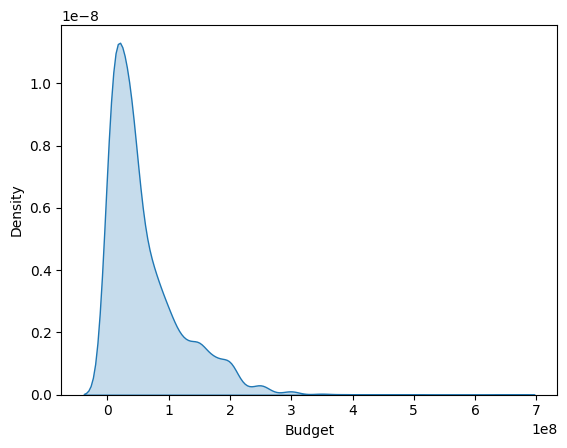

In [144]:
sns.kdeplot(movies,x="Budget",fill=True)

<Axes: xlabel='Revenue', ylabel='Density'>

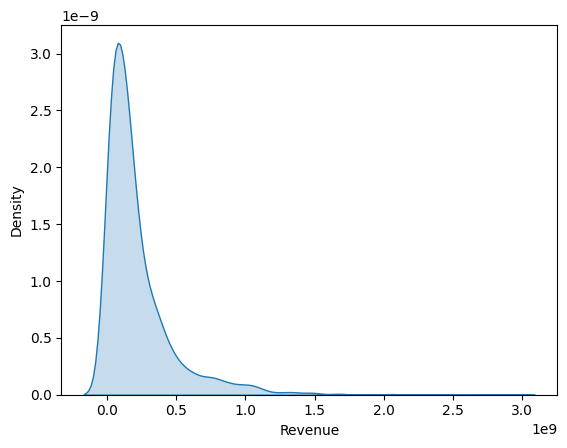

In [145]:
sns.kdeplot(movies,x="Revenue",fill=True)

<Axes: xlabel='Runtime'>

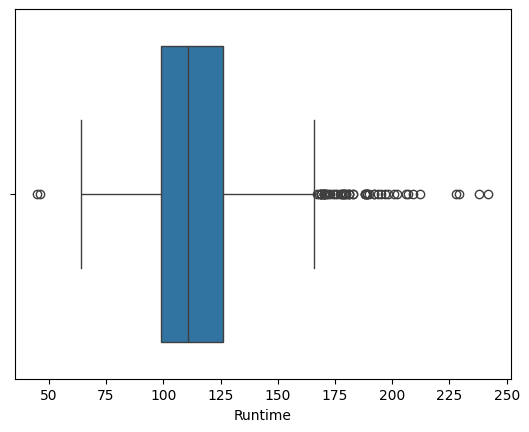

In [146]:
sns.boxplot(movies,x="Runtime")

<Axes: xlabel='Vote_Average', ylabel='Count'>

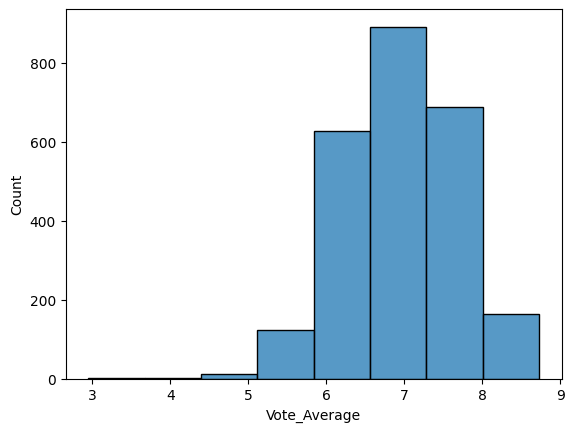

In [147]:
sns.histplot(movies,x="Vote_Average",bins=8)

In [148]:
genres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Genre_ID     19 non-null     int64 
 1   Genres_name  19 non-null     object
dtypes: int64(1), object(1)
memory usage: 436.0+ bytes


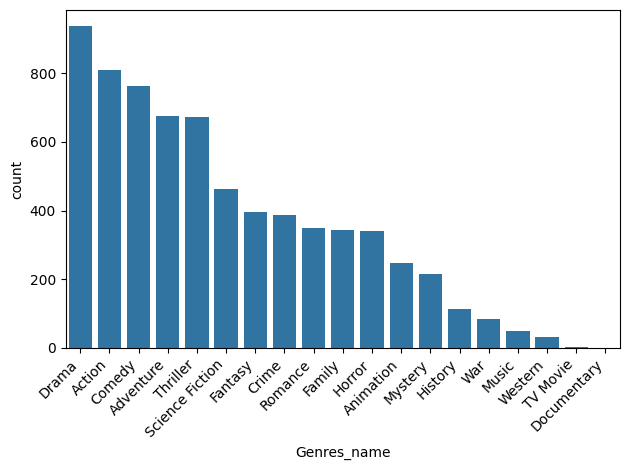

In [149]:
x = movie_genres.merge(genres, on="Genre_ID", how="inner")

sns.countplot(
    data=x,
    x="Genres_name",
    order=x["Genres_name"].value_counts().index
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

<Axes: xlabel='Budget', ylabel='Revenue'>

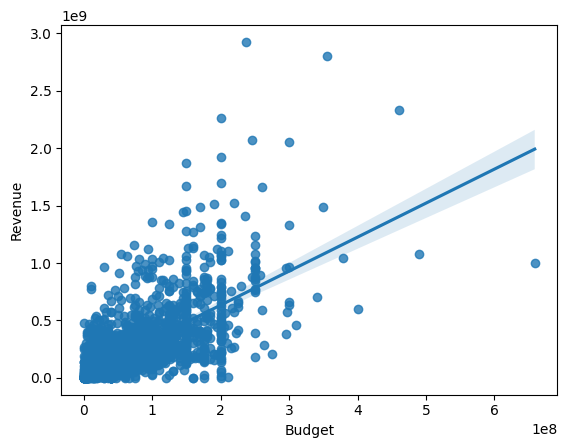

In [150]:
sns.regplot(movies,x="Budget",y="Revenue")

<Axes: xlabel='Popularity', ylabel='Vote_Count'>

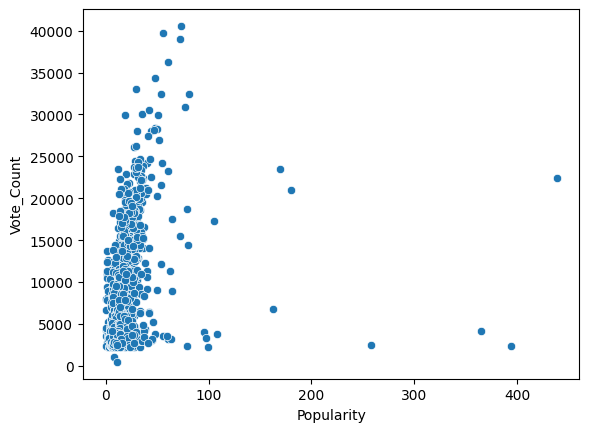

In [151]:
sns.scatterplot(movies,x="Popularity",y="Vote_Count")

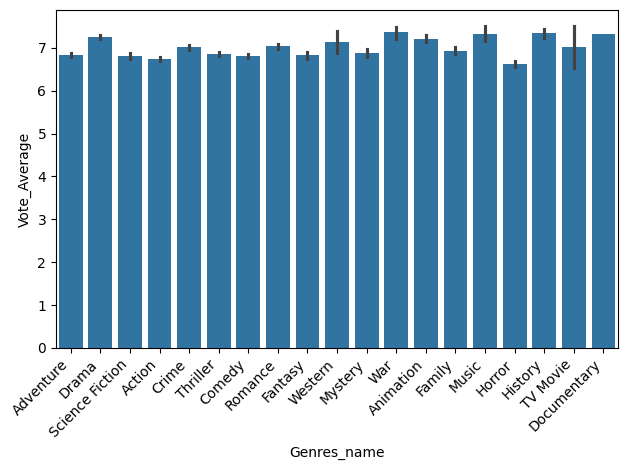

In [152]:
data = movie_genres.merge(genres, on="Genre_ID", how="inner").merge(movies,on="Movie_ID",how="inner")
sns.barplot(data,x="Genres_name",y="Vote_Average")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

In [153]:
movies["Release_Date"] = pd.to_datetime(movies["Release_Date"])

In [154]:
movies["Year_Release"]=movies["Release_Date"].dt.year

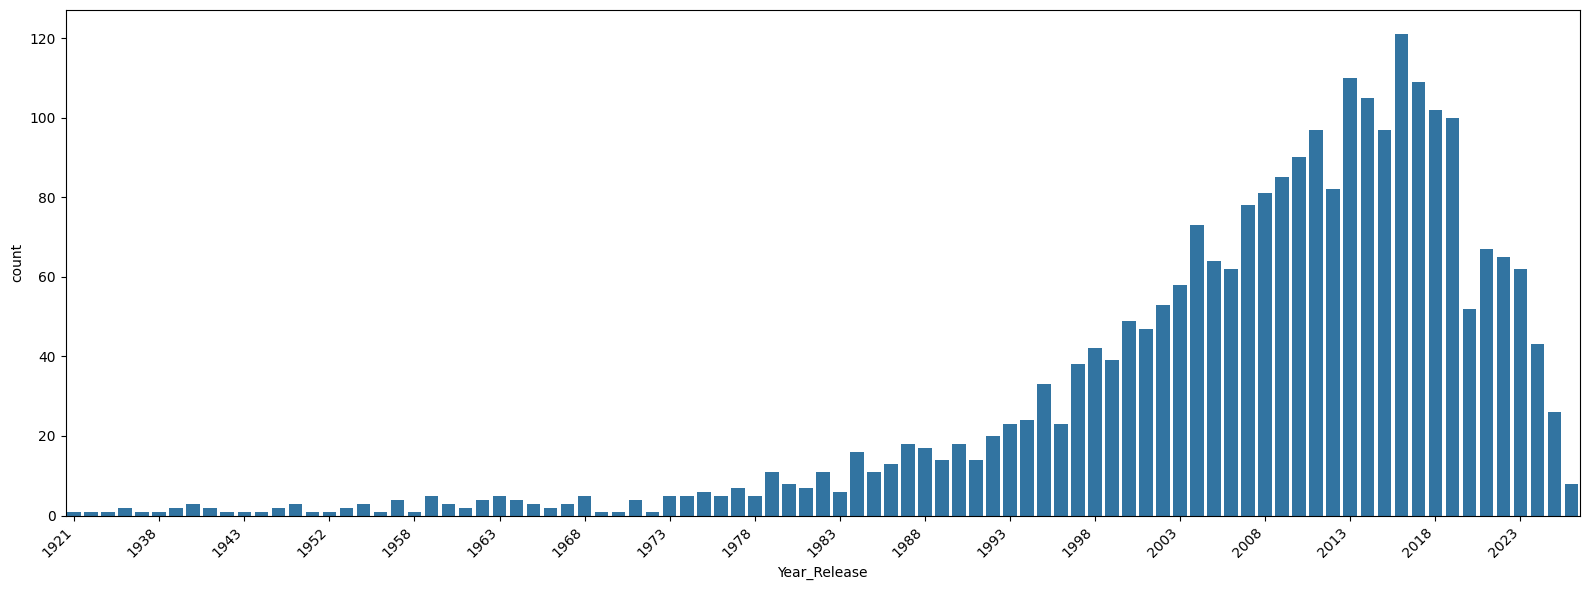

In [155]:
plt.figure(figsize=(16, 6))

sns.countplot(data=movies, x="Year_Release")

plt.xticks(ticks=range(0, len(movies["Year_Release"].value_counts().sort_index()), 5),labels=movies["Year_Release"].value_counts().sort_index().index[::5],rotation=45,ha="right")

plt.tight_layout()

<Axes: >

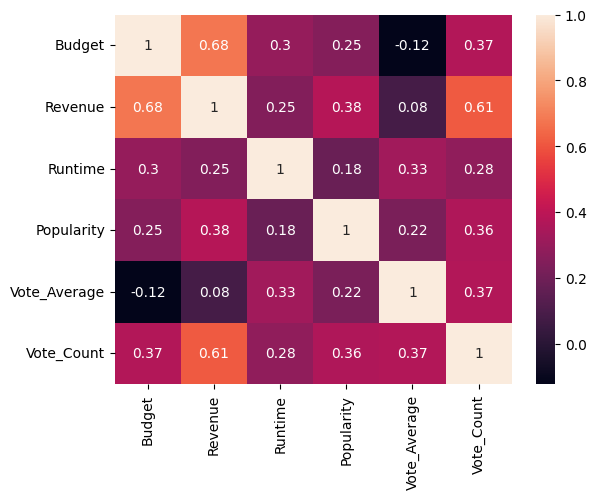

In [156]:
corr_df = movies[[
    "Budget",
    "Revenue",
    "Runtime",
    "Popularity",
    "Vote_Average",
    "Vote_Count"
]].corr()
sns.heatmap(corr_df,annot=True)

<Axes: xlabel='Budget', ylabel='Revenue'>

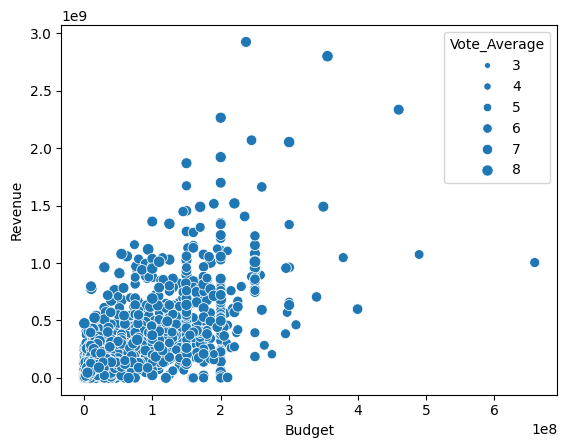

In [157]:
sns.scatterplot(movies,x="Budget",y="Revenue",size="Vote_Average")

In [158]:
temp=movies.merge(movie_genres,on="Movie_ID",how="inner").merge(genres,on="Genre_ID",how="inner").sort_values(by=["Movie_ID","Genre_ID"],ascending=[True,True])
temp[temp["Genre_ID"].isnull()]

,Movie_ID,Title,Original_Language,Release_Date,Runtime,Budget,Revenue,Popularity,Vote_Average,Vote_Count,Status,Overview,Year_Release,Genre_ID,Genres_name


In [159]:
temp

,Movie_ID,Title,Original_Language,Release_Date,Runtime,Budget,Revenue,Popularity,Vote_Average,Vote_Count,Status,Overview,Year_Release,Genre_ID,Genres_name
0,5,Four Rooms,en,1995-12-09,98,4000000.0,4257354.0,7.1595,5.908,2876,Released,It's Ted the Bellhop's first night on the job....,1995,35,Comedy
1,11,Star Wars,en,1977-05-25,121,11000000.0,775398007.0,44.3392,8.206,22582,Released,Princess Leia is captured and held hostage by ...,1977,12,Adventure
2,11,Star Wars,en,1977-05-25,121,11000000.0,775398007.0,44.3392,8.206,22582,Released,Princess Leia is captured and held hostage by ...,1977,28,Action
3,11,Star Wars,en,1977-05-25,121,11000000.0,775398007.0,44.3392,8.206,22582,Released,Princess Leia is captured and held hostage by ...,1977,878,Science Fiction
6,12,Finding Nemo,en,2003-05-30,100,94000000.0,940335536.0,32.5563,7.820,20748,Released,"Nemo, an adventurous young clownfish, is unexp...",2003,12,Adventure
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6873,1304313,Lee Cronin's The Mummy,en,2026-04-15,133,22000000.0,90552113.0,79.4601,7.943,2430,Released,The young daughter of a journalist disappears ...,2026,27,Horror
6874,1339713,Obsession,en,2026-05-13,109,750000.0,474895195.0,364.8720,8.248,4203,Released,"After breaking the mysterious ""One Wish Willow...",2026,27,Horror
6875,1339713,Obsession,en,2026-05-13,109,750000.0,474895195.0,364.8720,8.248,4203,Released,"After breaking the mysterious ""One Wish Willow...",2026,53,Thriller
6877,1368166,The Housemaid,en,2025-12-18,131,35000000.0,399644671.0,41.4337,7.269,2789,Released,"Trying to escape her past, Millie Calloway acc...",2025,53,Thriller


In [160]:
primary_genre = temp.drop_duplicates(subset="Movie_ID", keep="first")[["Movie_ID", "Genres_name"]]

In [161]:
movies = movies.merge(primary_genre, on="Movie_ID", how="left")

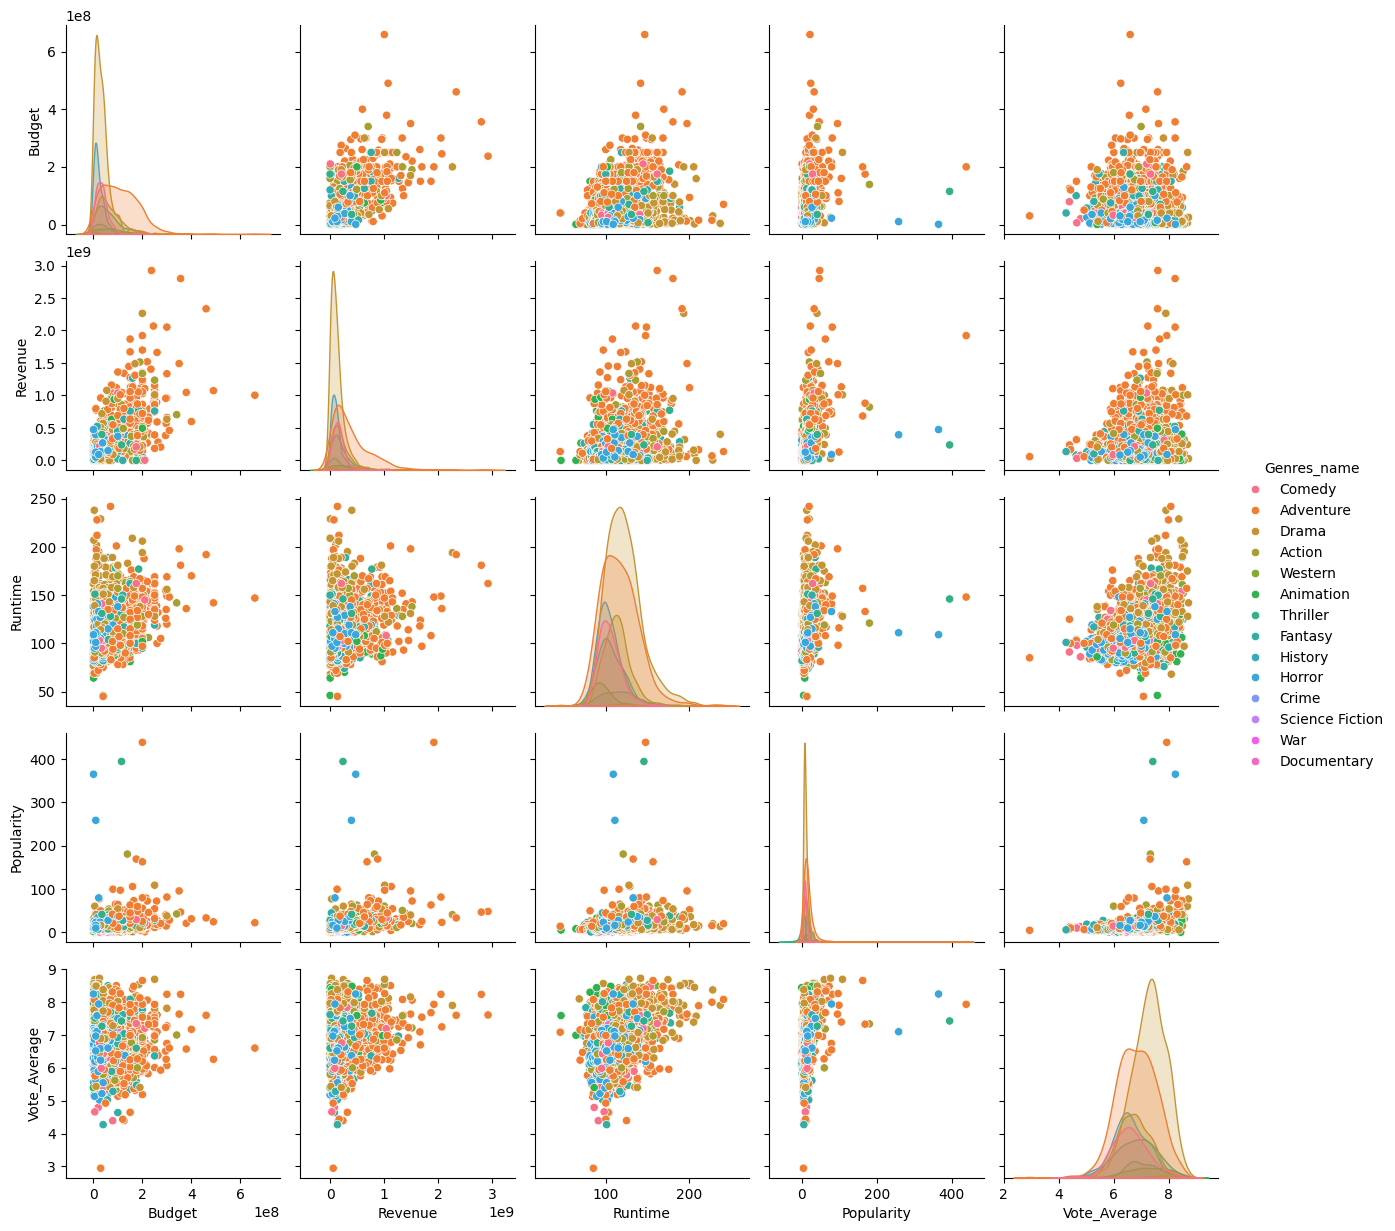

In [162]:
sns.pairplot(movies,vars=["Budget","Revenue","Runtime","Popularity","Vote_Average"],hue="Genres_name")
plt.show()

<Axes: xlabel='Budget', ylabel='Revenue'>

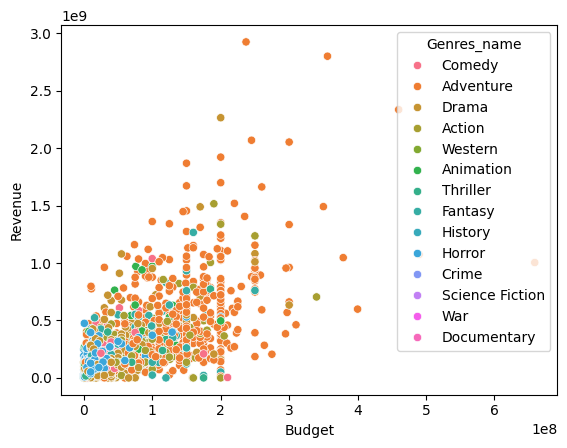

In [163]:
sns.scatterplot(movies,x="Budget",y="Revenue",hue="Genres_name")

In [165]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2503 entries, 0 to 2502
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Movie_ID           2503 non-null   int64         
 1   Title              2503 non-null   object        
 2   Original_Language  2503 non-null   object        
 3   Release_Date       2503 non-null   datetime64[ns]
 4   Runtime            2503 non-null   int64         
 5   Budget             2503 non-null   float64       
 6   Revenue            2503 non-null   float64       
 7   Popularity         2503 non-null   float64       
 8   Vote_Average       2503 non-null   float64       
 9   Vote_Count         2503 non-null   int64         
 10  Status             2503 non-null   object        
 11  Overview           2503 non-null   object        
 12  Year_Release       2503 non-null   int32         
 13  Genres_name        2499 non-null   object        
 14  Release_

In [169]:
temp = (movies.merge(movie_genres, on="Movie_ID", how="inner").merge(genres, on="Genre_ID", how="inner"))
temp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6878 entries, 0 to 6877
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Movie_ID           6878 non-null   int64         
 1   Title              6878 non-null   object        
 2   Original_Language  6878 non-null   object        
 3   Release_Date       6878 non-null   datetime64[ns]
 4   Runtime            6878 non-null   int64         
 5   Budget             6878 non-null   float64       
 6   Revenue            6878 non-null   float64       
 7   Popularity         6878 non-null   float64       
 8   Vote_Average       6878 non-null   float64       
 9   Vote_Count         6878 non-null   int64         
 10  Status             6878 non-null   object        
 11  Overview           6878 non-null   object        
 12  Year_Release       6878 non-null   int32         
 13  Genres_name_x      6878 non-null   object        
 14  Release_

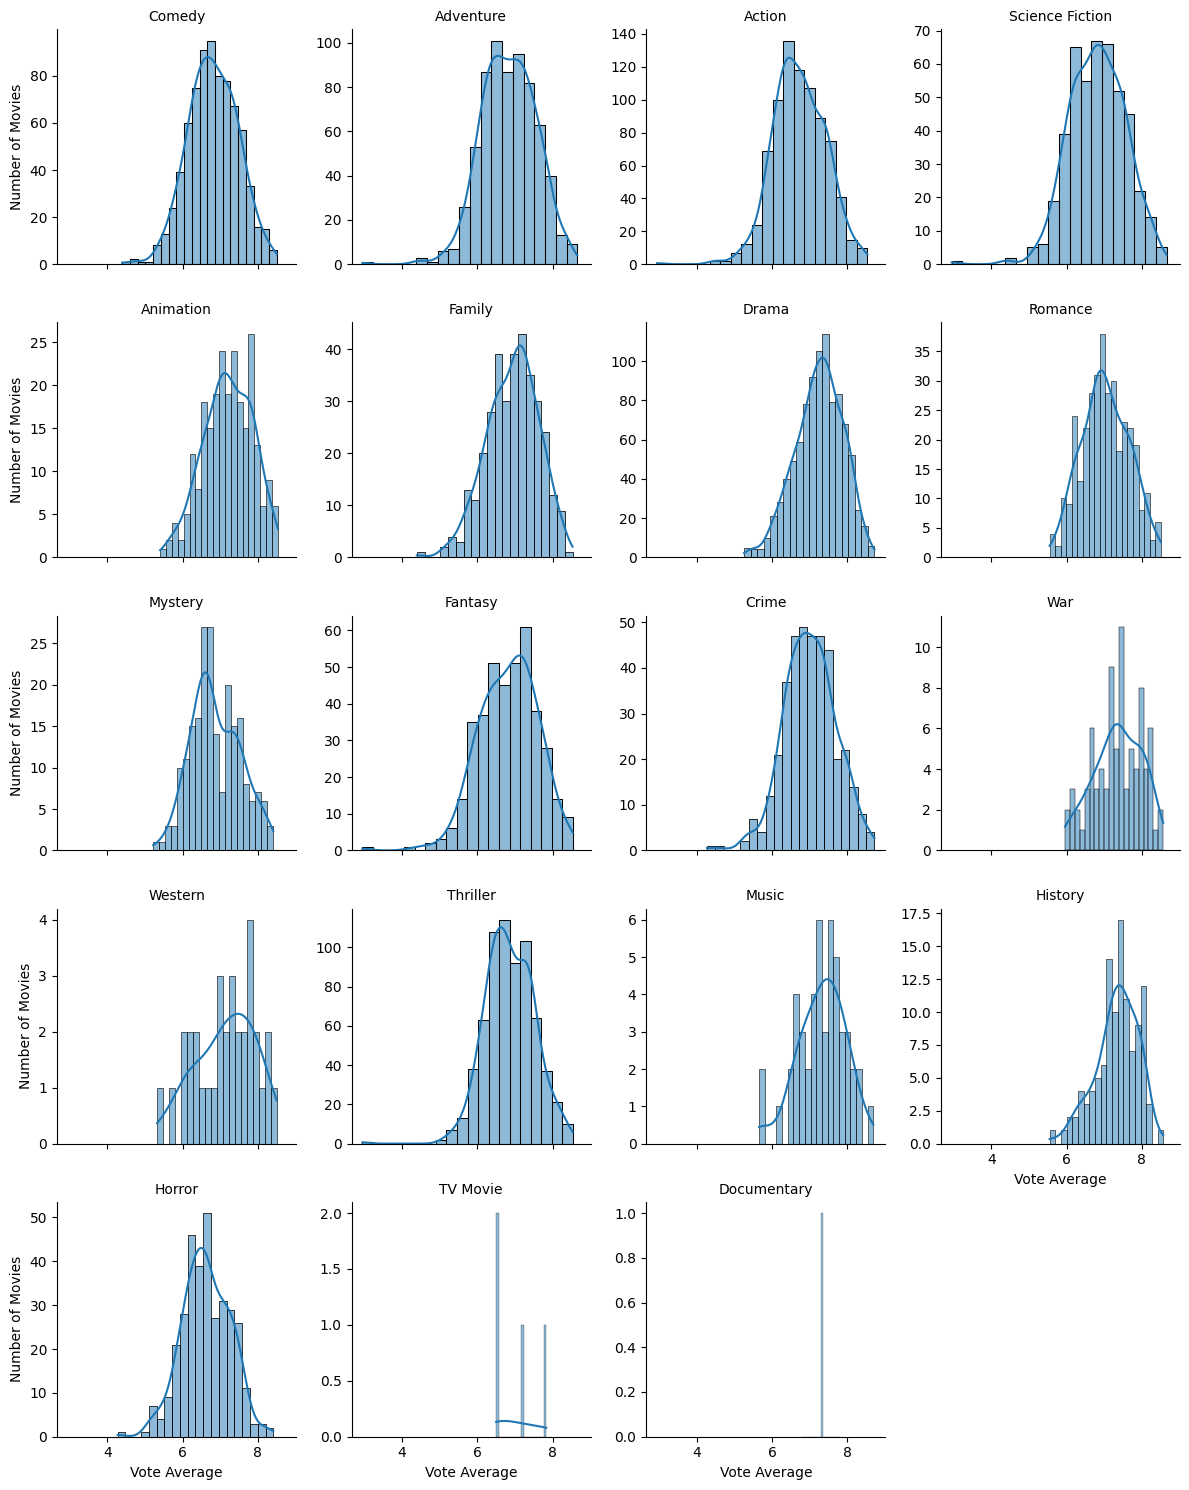

In [170]:
temp = (movies.merge(movie_genres, on="Movie_ID", how="inner").merge(genres, on="Genre_ID", how="inner"))

g = sns.FacetGrid(temp, col="Genres_name_y", col_wrap=4, sharex=True, sharey=False)

g.map(sns.histplot, "Vote_Average", bins=20, kde=True)

g.set_axis_labels("Vote Average", "Number of Movies")
g.set_titles("{col_name}")

plt.tight_layout()
plt.show()

<Axes: xlabel='Release_Decade', ylabel='Genres_name_y'>

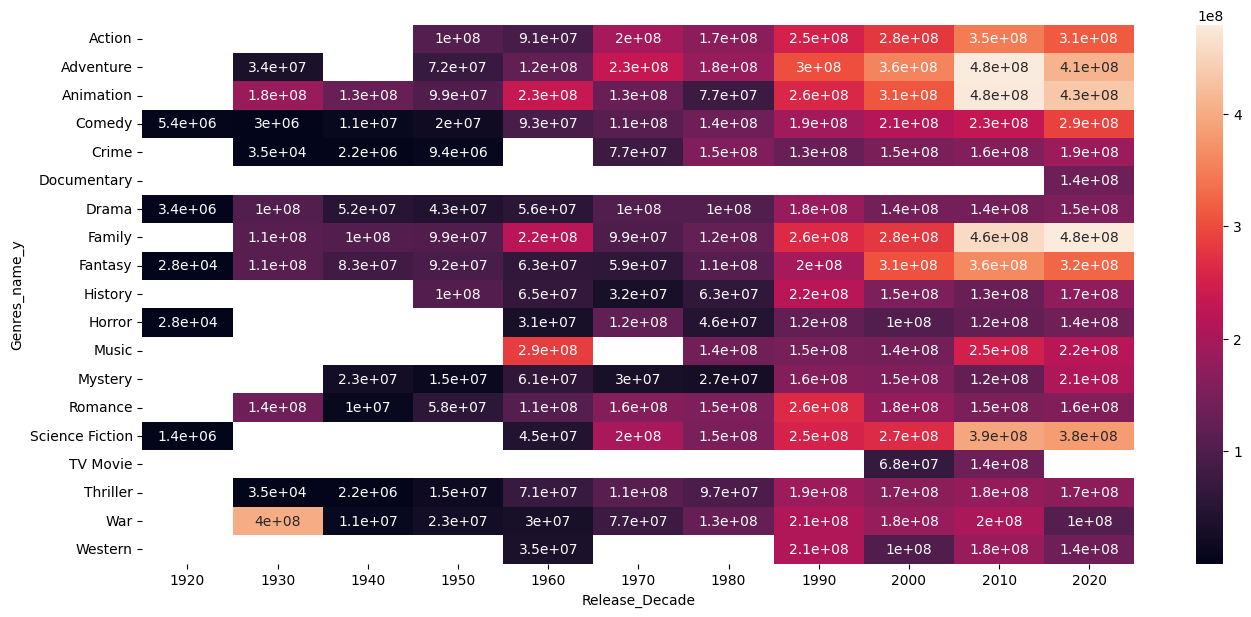

In [164]:
movies["Release_Decade"] = (movies["Release_Date"].dt.year // 10) * 10
pivot=movies.merge(movie_genres,on="Movie_ID",how="inner").merge(genres,on="Genre_ID",how="inner").pivot_table(index="Genres_name_y",columns="Release_Decade",values="Revenue",aggfunc="mean")
plt.figure(figsize=(16, 7))
sns.heatmap(pivot, annot=True)